<a href="https://colab.research.google.com/github/Shiva2259839/Mapping-Arc/blob/main/Bundelkhand_sample_map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install geopandas cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 13.5 MB/s  0:00:00


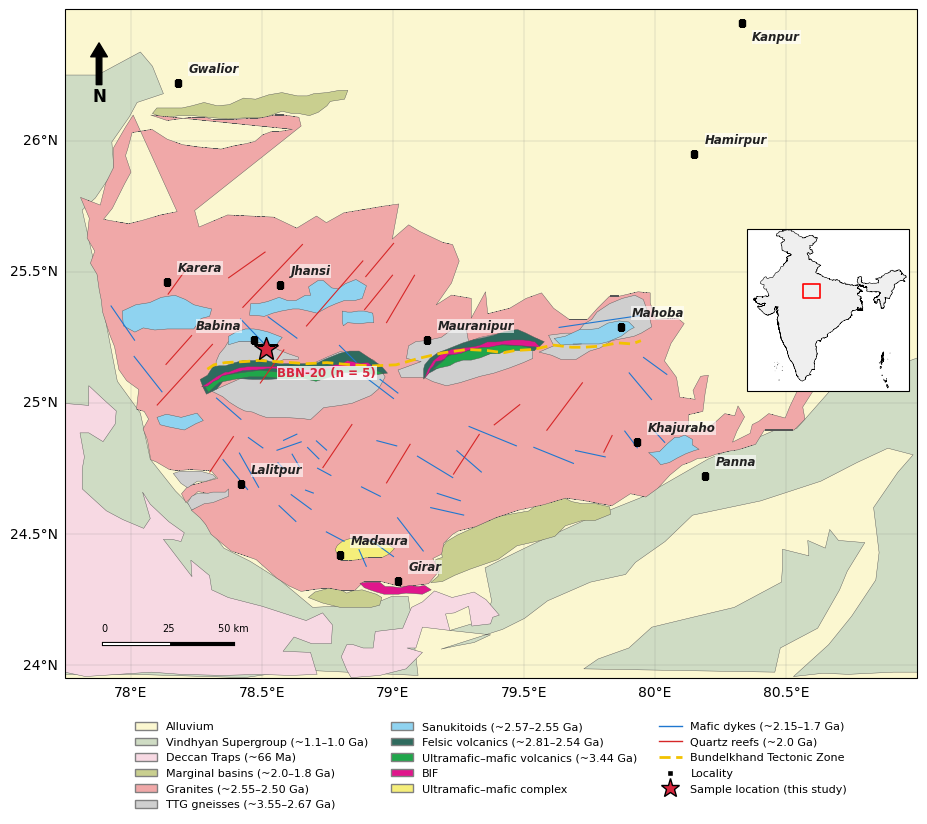

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from shapely.geometry import box
from shapely.validation import make_valid
import numpy as np
import cartopy.crs as ccrs

pc = ccrs.PlateCarree()
units = gpd.read_file("bundelkhand_units.geojson").set_crs("EPSG:4326", allow_override=True)
lines = gpd.read_file("bundelkhand_lines.geojson").set_crs("EPSG:4326", allow_override=True)
india = gpd.read_file("https://raw.githubusercontent.com/datameet/maps/master/Country/india-composite.geojson").to_crs("EPSG:4326")
nm = units["name"].str.lower()

def pick(test):
    return units[nm.apply(test)].geometry.apply(make_valid)

# (geometry, rang, legend) -- neeche se upar
LAYERS = [
    (pick(lambda s: "vindhyan" in s), "#cfdcc4", "Vindhyan Supergroup (~1.1–1.0 Ga)"),
    (pick(lambda s: "deccan" in s), "#f7d9e3", "Deccan Traps (~66 Ma)"),
    (pick(lambda s: "basin" in s), "#c9cf8f", "Marginal basins (~2.0–1.8 Ga)"),
    (pick(lambda s: "granite" in s), "#f0a8a8", "Granites (~2.55–2.50 Ga)"),
    (pick(lambda s: "ttg" in s), "#cfcfcf", "TTG gneisses (~3.55–2.67 Ga)"),
    (pick(lambda s: "sanukitoid" in s), "#8fd3f0", "Sanukitoids (~2.57–2.55 Ga)"),
    (pick(lambda s: "felsic" in s or "greenstone" in s), "#2f6b5e", "Felsic volcanics (~2.81–2.54 Ga)"),
    (pick(lambda s: "ultramafic" in s and "complex" not in s), "#1fa64a", "Ultramafic–mafic volcanics (~3.44 Ga)"),
    (pick(lambda s: "bif" in s), "#e0168c", "BIF"),
    (pick(lambda s: "complex" in s), "#f5ee7a", "Ultramafic–mafic complex"),
]
ALLUVIUM = "#fbf7d0"

def get_lines(word):
    return lines[lines["name"].str.lower().str.startswith(word)].geometry

fig = plt.figure(figsize=(11, 10))
ax = plt.axes(projection=pc)
ax.set_extent([77.75, 81.0, 23.95, 26.5], crs=pc)
ax.set_facecolor(ALLUVIUM)

for z, (g, c, _) in enumerate(LAYERS, start=1):
    ax.add_geometries(g, crs=pc, facecolor=c, edgecolor="#555555", linewidth=0.3, zorder=z)
ax.add_geometries(get_lines("dyke"), crs=pc, facecolor="none", edgecolor="#1f77d0", linewidth=0.8, zorder=12)
ax.add_geometries(get_lines("reef"), crs=pc, facecolor="none", edgecolor="#d62728", linewidth=0.8, zorder=12)
ax.add_geometries(get_lines("btz"), crs=pc, facecolor="none", edgecolor="#f2c200",
                  linewidth=2, linestyle=(0, (4, 2)), zorder=13)

# --- shahar ---
towns = {"Gwalior": (78.18, 26.22), "Jhansi": (78.57, 25.45), "Karera": (78.14, 25.46),
         "Babina": (78.47, 25.24), "Mauranipur": (79.13, 25.24), "Mahoba": (79.87, 25.29),
         "Khajuraho": (79.93, 24.85), "Panna": (80.19, 24.72), "Lalitpur": (78.42, 24.69),
         "Hamirpur": (80.15, 25.95), "Madaura": (78.80, 24.42), "Girar": (79.02, 24.32),
         "Kanpur": (80.33, 26.45)}
offs = {"Babina": (-0.22, 0.04), "Kanpur": (0.04, -0.07)}
for t, (x, y) in towns.items():
    ax.plot(x, y, "ks", markersize=4, transform=pc, zorder=18)
    dx, dy = offs.get(t, (0.04, 0.04))
    ax.text(x + dx, y + dy, t, transform=pc, fontsize=8.5, style="italic",
            color="#222222", fontweight="semibold", zorder=18,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.6, pad=0.3))

# --- samples: ek tara Babina par ---
ax.plot(78.515, 25.205, marker="*", color="#d7263d", markeredgecolor="black",
        markersize=18, transform=pc, zorder=30)
ax.text(78.56, 25.10, "BBN-20 (n = 5)", transform=pc, fontsize=8.5, fontweight="bold",
        color="#d7263d", zorder=31,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5))

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.5)
gl.top_labels = gl.right_labels = False

# --- scale bar 50 km ---
lat0, lon0, km = 24.08, 77.9, 50
dlon = km / (111.32 * np.cos(np.radians(lat0)))
ax.plot([lon0, lon0 + dlon], [lat0, lat0], color="black", linewidth=3, transform=pc, zorder=25)
ax.plot([lon0, lon0 + dlon/2], [lat0, lat0], color="white", linewidth=1.5, transform=pc, zorder=26)
for x, t in [(lon0, "0"), (lon0 + dlon/2, "25"), (lon0 + dlon, "50 km")]:
    ax.text(x, lat0 + 0.05, t, transform=pc, ha="center", fontsize=7, zorder=26)

# --- north arrow ---
ax.annotate("N", xy=(0.04, 0.95), xytext=(0.04, 0.87), xycoords="axes fraction",
            ha="center", va="center", fontsize=12, fontweight="bold", zorder=27,
            arrowprops=dict(facecolor="black", width=4, headwidth=12, headlength=10))

# --- India inset (upar daayein, alluvium wali khaali jagah) ---
ins = ax.inset_axes([0.80, 0.40, 0.19, 0.30], projection=pc)
ins.set_extent([67, 98, 6, 37], crs=pc)
ins.add_geometries(india.geometry, crs=pc, facecolor="#efefef", edgecolor="black", linewidth=0.4)
ins.add_geometries([box(77.75, 23.95, 81.0, 26.5)], crs=pc, facecolor="none",
                   edgecolor="red", linewidth=1.2)
ins.set_zorder(40)

# --- legend (naksha ke neeche) ---
handles = [mpatches.Patch(facecolor=ALLUVIUM, edgecolor="grey", label="Alluvium")]
handles += [mpatches.Patch(facecolor=c, edgecolor="grey", label=l) for _, c, l in LAYERS]
handles += [
    Line2D([], [], color="#1f77d0", linewidth=1, label="Mafic dykes (~2.15–1.7 Ga)"),
    Line2D([], [], color="#d62728", linewidth=1, label="Quartz reefs (~2.0 Ga)"),
    Line2D([], [], color="#f2c200", linewidth=2, linestyle=(0, (4, 2)), label="Bundelkhand Tectonic Zone"),
    Line2D([], [], color="w", marker="s", markerfacecolor="black", markersize=5, label="Locality"),
    Line2D([], [], color="w", marker="*", markerfacecolor="#d7263d", markeredgecolor="black",
           markersize=14, label="Sample location (this study)"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3,
          fontsize=8, frameon=False)

plt.savefig("bundelkhand_samples.png", dpi=600, bbox_inches="tight")
plt.savefig("bundelkhand_samples.pdf", bbox_inches="tight")
plt.show()